# Workbook 4 · Trade studies: sweeps, chaining, and a plot you can put in a review

One variant answers "what if?". A **sweep** answers "how does it scale?". This workbook runs two sweeps the right way (each solve warm-started from its
neighbour), plots them, and turns them into the numbers a review asks for: a slope, a growth factor, and the point where something changes.

**Run time:** about 4-5 minutes (about ten solves).

In [1]:
import sys
from pathlib import Path
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(repo_root / "tutorials"))
from sizing_workbench import *
from dataclasses import replace
import numpy as onp
base = baseline_variant()

## 1. A range sweep, chained

Chaining means each solve starts from the previous one (`start=previous`), which is faster and more robust than starting every point from the baseline, because
neighbours are close. Sweep 350 to 600 nm:

[350 nm: sized in 96 s from 'baseline': 13,764 lb]


[400 nm: sized in 104 s from '350 nm': 14,211 lb]


[500 nm: sized in 125 s from 'baseline': 15,664 lb]


[550 nm: sized in 116 s from '500 nm': 16,163 lb]


[600 nm: sized in 100 s from '550 nm': 16,796 lb]


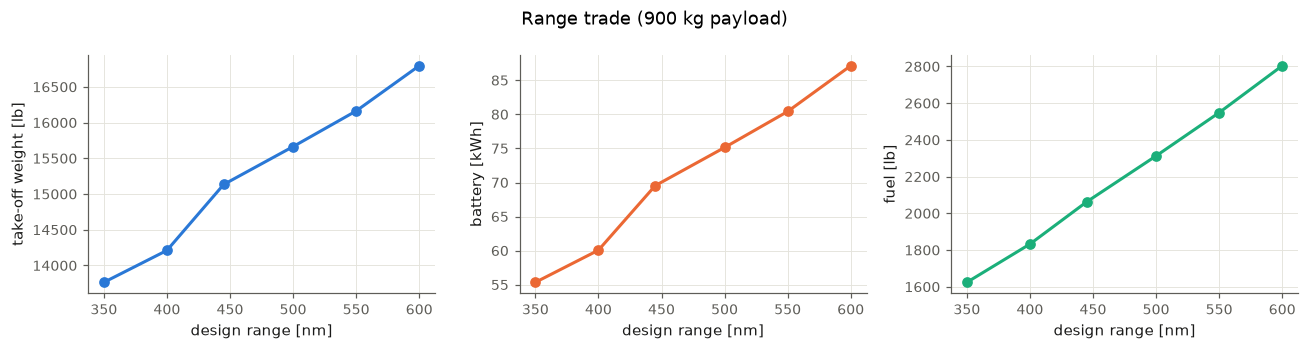

In [2]:
ranges_nm = [350, 400, 445, 500, 550, 600]
sweep_range, previous = [], base
for range_nm in ranges_nm:
    if range_nm == 445:
        variant = base                                  # the baseline is the 445 nm point
    else:
        variant = size(f"{range_nm} nm", requirements=replace(base.requirements, range_m=range_nm * 1852.0), start=previous)
    sweep_range.append(variant)
    previous = variant
plot_trade(sweep_range, ranges_nm, "design range [nm]", "Range trade (900 kg payload)")

In [3]:
weights_lb = onp.array([lb(v.result.mass_takeoff_kg) for v in sweep_range])
slope = onp.polyfit(ranges_nm, weights_lb, 1)[0]
print(f"take-off weight grows about {slope:.1f} lb per nm (linear fit over 350-600 nm)")
check("take-off weight rises with range", onp.all(onp.diff(weights_lb) > 0))
units = [(v.result.machine_units["motor"][1], v.result.machine_units["generator"][1]) for v in sweep_range]
print("machine units (motor, generator) along the sweep:", dict(zip(ranges_nm, units)))

take-off weight grows about 12.3 lb per nm (linear fit over 350-600 nm)
PASS  take-off weight rises with range
machine units (motor, generator) along the sweep: {350: (2, 2), 400: (2, 2), 445: (2, 3), 500: (2, 3), 550: (2, 3), 600: (2, 3)}


Look for steps in the curve where a machine-unit count changes: the slope is not one number across a unit boundary. That is worth saying in a review: *"between
X and Y nm the generators need a third unit."*

## 2. A payload sweep and the growth factor

[800 kg: sized in 54 s from 'baseline': 14,078 lb]


[1000 kg: sized in 31 s from 'baseline': 15,690 lb]


[700 kg: sized in 42 s from '800 kg': 13,539 lb]


[1100 kg: sized in 30 s from '1000 kg': 16,252 lb]


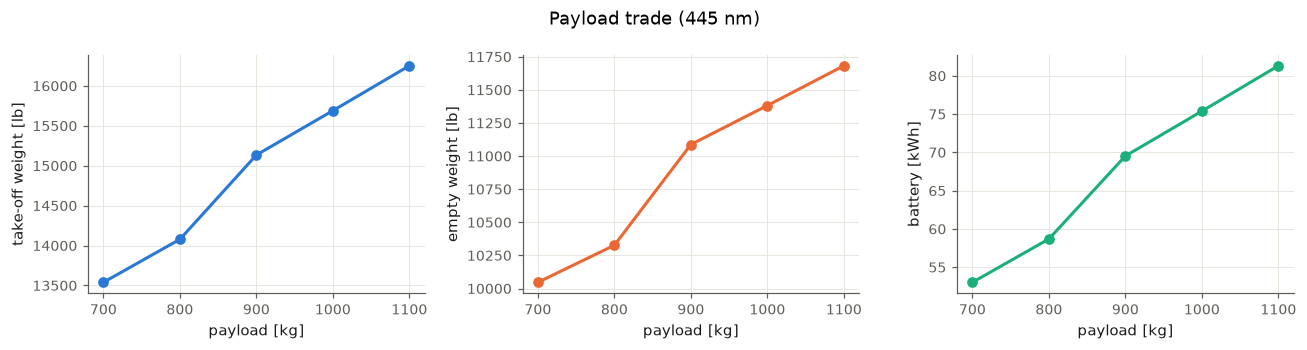

   700-800 kg: growth factor 2.44
   800-900 kg: growth factor 4.79
   900-1000 kg: growth factor 2.52
   1000-1100 kg: growth factor 2.55
PASS  every payload step costs more than its own mass


In [4]:
payloads_kg = [700.0, 800.0, 900.0, 1000.0, 1100.0]
sweep_payload, previous = [], base
for payload_kg in sorted(payloads_kg, key=lambda p: abs(p - 900.0)):        # outward from the baseline, so neighbours chain
    if payload_kg == 900.0:
        variant = base
    else:
        neighbour = min(sweep_payload, key=lambda v: abs(v.result.mass_payload_kg - payload_kg)) if sweep_payload else base
        variant = size(f"{payload_kg:.0f} kg", requirements=replace(base.requirements, mass_payload_kg=payload_kg), start=neighbour)
    sweep_payload.append(variant)
sweep_payload.sort(key=lambda v: v.result.mass_payload_kg)
payload_values = [v.result.mass_payload_kg for v in sweep_payload]
plot_trade(sweep_payload, payload_values, "payload [kg]", "Payload trade (445 nm)", quantities=("take-off weight [lb]", "empty weight [lb]", "battery [kWh]"))
masses = onp.array([v.result.mass_takeoff_kg for v in sweep_payload])
growth = onp.diff(masses) / onp.diff(payload_values)
for (p0, p1), g in zip(zip(payload_values[:-1], payload_values[1:]), growth):
    print(f"   {p0:.0f}-{p1:.0f} kg: growth factor {g:.2f}")
check("every payload step costs more than its own mass", onp.all(growth > 1))

The growth factor is about 2.5 on average, with bumps where a unit count changes. Any kilogram added anywhere (an empty-weight overrun, a heavier sensor) costs
about that much at take-off, which is why tutorial 23's empty-weight uncertainty matters.

## 3. Your turn: a sweep of your own

Pick an input and sweep it. The template sweeps the hover altitude; change `values` and the `replace(...)` line.

[hover 3000 ft: sized in 62 s from 'baseline': 14,625 lb]


[hover 5000 ft: sized in 46 s from 'baseline': 15,236 lb]


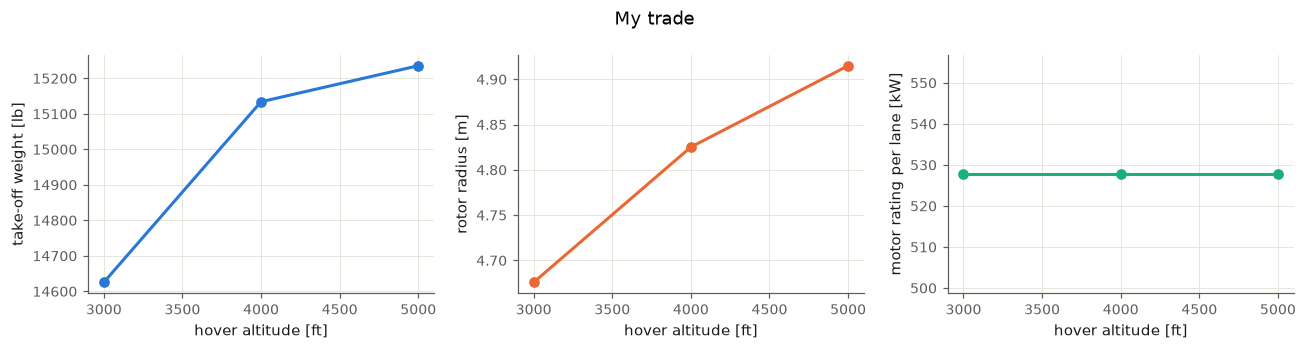

In [5]:
values = [3000.0, 4000.0, 5000.0]                      # <- edit: hover altitude in ft (4,000 ft in the baseline)
mine, previous = [], base
for value in values:
    requirements = replace(base.requirements, altitude_hover_m=value * u.foot)      # <- edit: the field you sweep
    variant = base if value == 4000.0 else size(f"hover {value:.0f} ft", requirements=requirements, start=previous)
    mine.append(variant)
    previous = variant
plot_trade(mine, values, "hover altitude [ft]", "My trade", quantities=("take-off weight [lb]", "rotor radius [m]", "motor rating per lane [kW]"))

<details><summary>Ideas and what to expect</summary>

- **Hover altitude:** thinner air needs more rotor power; the rotor radius is already capped by the span, so the drive and motors grow. Expect a steep slope.
- **Engine power** (`assumptions=replace(base.assumptions, power_rated_turboshaft_fixed_W=hp * u.hp)`): weight is lowest near the power the mission needs; above it
  you carry unused engine, below it the battery and hovers suffer, and too low becomes infeasible.
- **Cell power density** (`factor_power_density_battery`): big gains at first, flattening once another constraint binds.

If a point fails from its neighbour, `size` falls back to the full strategy automatically (slower). Infeasible points (no aircraft meets the requirements) raise
an error: that is information, not a bug.
</details>

## Making it presentable

For a review, a trade plot needs: the baseline marked, the binding driver named on each side of any kink, and units in the axis labels. `compare(...)` on the end
points gives the table under the plot, and `binding_changes(first, last)` gives the sentence that explains the slope.

In [6]:
compare(sweep_range[0], base, sweep_range[-1])
binding_changes(sweep_range[0], sweep_range[-1])

                                              350 nm                baseline                  600 nm
take-off weight [lb]                          13,764         15,134 (+10.0%)         16,796 (+22.0%)
empty weight [lb]                             10,156          11,087 (+9.2%)         12,008 (+18.2%)
payload [lb]                                   1,984           1,984 (+0.0%)           1,984 (+0.0%)
fuel [lb]                                      1,624          2,063 (+27.0%)          2,804 (+72.6%)
battery [kWh]                                   55.4           69.5 (+25.6%)           87.1 (+57.4%)
wing area [m2]                                 21.54           23.24 (+7.9%)          25.28 (+17.4%)
span [m]                                       11.48           11.93 (+3.9%)           12.44 (+8.3%)
rotor radius [m]                               4.603           4.825 (+4.8%)          5.082 (+10.4%)
disk loading [kg/m2]                            46.9            46.9 (+0.1%)            47.

## What you practised

- Chain sweeps (`start=previous`) so each solve begins next to its answer.
- Turn sweeps into slopes, growth factors and named breakpoints (unit-count steps, binding changes).
- An infeasible point is a result: the requirements have run out of aircraft.

You have now sized variants of every kind the model supports: mission, requirements, engines, technology, architecture and models. To change the model itself
(a new component, requirement or segment), go to tutorial 20, section 5.

In [7]:
check_summary()

2 of 2 checks passed
